# Remove Long Duration Trips (Two-Stage Filtering)
## Stage 1: Remove 99% of Trips Above 600 Minutes
## Stage 2: Remove 95% of Trips Above 350 Minutes

This notebook:
1. Loads the original CSV file
2. Calculates trip duration
3. **Stage 1**: Randomly removes 99% of trips over 600 minutes (extreme outliers)
4. **Stage 2**: Randomly removes 95% of trips over 350 minutes (long trips)
5. Saves the filtered data back to the same CSV file

**Purpose**: Two-stage filtering to aggressively reduce extreme outliers while moderately reducing long trips, keeping some samples for diversity.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

## 1. Load Original Data

In [12]:
# Load original CSV
csv_file = 'bq-results-20251021-151536-1761059869369.csv'
df = pd.read_csv(csv_file, dtype_backend='pyarrow')

print("="*80)
print("ORIGINAL DATASET")
print("="*80)
print(f"Shape: {df.shape}")
print(f"Total trips: {len(df):,}")
print("\nColumns:")
print(df.columns.tolist())

ORIGINAL DATASET
Shape: (1065046, 24)
Total trips: 1,065,046

Columns:
['vendor_id', 'pickup_datetime', 'dropoff_datetime', 'store_and_fwd_flag', 'rate_code', 'passenger_count', 'trip_distance', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'ehail_fee', 'airport_fee', 'total_amount', 'payment_type', 'distance_between_service', 'time_between_service', 'trip_type', 'imp_surcharge', 'pickup_location_id', 'dropoff_location_id', 'data_file_year', 'data_file_month']


## 2. Calculate Trip Duration

In [13]:
# Convert datetime columns
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['dropoff_datetime'] = pd.to_datetime(df['dropoff_datetime'])

# Calculate trip duration in minutes
df['trip_duration'] = (df['dropoff_datetime'] - df['pickup_datetime']).dt.total_seconds() / 60

print("\nTrip Duration Statistics:")
print(df['trip_duration'].describe())


Trip Duration Statistics:
count    1.065046e+06
mean     1.997653e+01
std      1.765926e+01
min     -4.398333e+01
25%      8.733333e+00
50%      1.500000e+01
75%      2.600000e+01
max      1.434783e+03
Name: trip_duration, dtype: float64


## 3. Analyze Trip Duration Distribution

In [14]:
# Define thresholds for two-stage filtering
threshold_extreme = 600  # Stage 1: Extreme outliers
threshold_long = 350     # Stage 2: Long trips

# Identify trips in different categories
extreme_trips = df['trip_duration'] > threshold_extreme
long_trips = (df['trip_duration'] > threshold_long) & (df['trip_duration'] <= threshold_extreme)
normal_trips = df['trip_duration'] <= threshold_long

print("="*80)
print("TRIPS ANALYSIS (Two-Stage Thresholds)")
print("="*80)
print(f"\nTrips <= {threshold_long} minutes (Normal):        {normal_trips.sum():,} ({normal_trips.sum()/len(df)*100:.2f}%)")
print(f"Trips {threshold_long}-{threshold_extreme} minutes (Long):      {long_trips.sum():,} ({long_trips.sum()/len(df)*100:.2f}%)")
print(f"Trips > {threshold_extreme} minutes (Extreme):       {extreme_trips.sum():,} ({extreme_trips.sum()/len(df)*100:.2f}%)")

print(f"\nExtreme trips statistics (>{threshold_extreme} min):")
print(df[extreme_trips]['trip_duration'].describe())

print(f"\nLong trips statistics ({threshold_long}-{threshold_extreme} min):")
print(df[long_trips]['trip_duration'].describe())

TRIPS ANALYSIS (Two-Stage Thresholds)

Trips <= 350 minutes (Normal):        1,065,036 (100.00%)
Trips 350-600 minutes (Long):      8 (0.00%)
Trips > 600 minutes (Extreme):       2 (0.00%)

Extreme trips statistics (>600 min):
count       2.000000
mean     1417.891667
std        23.888424
min      1401.000000
25%      1409.445833
50%      1417.891667
75%      1426.337500
max      1434.783333
Name: trip_duration, dtype: float64

Long trips statistics (350-600 min):
count      8.000000
mean     385.062500
std       18.949818
min      355.466667
25%      378.241667
50%      382.175000
75%      390.029167
max      421.333333
Name: trip_duration, dtype: float64


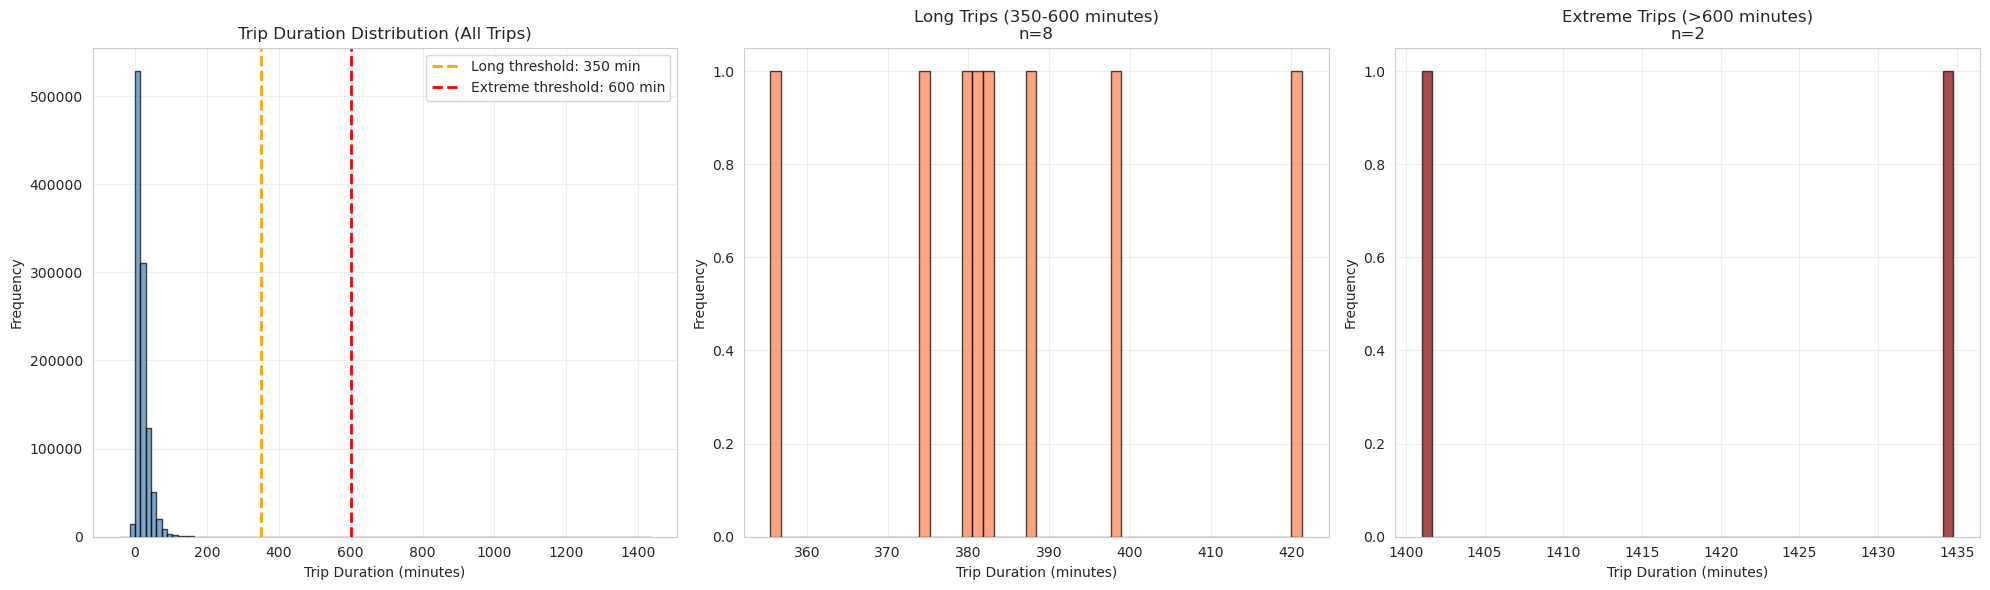

In [15]:
# Visualize distribution
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Histogram of all trips
axes[0].hist(df['trip_duration'], bins=100, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].axvline(threshold_long, color='orange', linestyle='--', linewidth=2, label=f'Long threshold: {threshold_long} min')
axes[0].axvline(threshold_extreme, color='red', linestyle='--', linewidth=2, label=f'Extreme threshold: {threshold_extreme} min')
axes[0].set_xlabel('Trip Duration (minutes)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Trip Duration Distribution (All Trips)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Long trips (350-600 min)
long_trip_data = df[long_trips]['trip_duration']
axes[1].hist(long_trip_data, bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[1].set_xlabel('Trip Duration (minutes)')
axes[1].set_ylabel('Frequency')
axes[1].set_title(f'Long Trips ({threshold_long}-{threshold_extreme} minutes)\nn={len(long_trip_data):,}')
axes[1].grid(True, alpha=0.3)

# Extreme trips (>600 min)
extreme_trip_data = df[extreme_trips]['trip_duration']
axes[2].hist(extreme_trip_data, bins=50, edgecolor='black', alpha=0.7, color='darkred')
axes[2].set_xlabel('Trip Duration (minutes)')
axes[2].set_ylabel('Frequency')
axes[2].set_title(f'Extreme Trips (>{threshold_extreme} minutes)\nn={len(extreme_trip_data):,}')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Two-Stage Random Removal

In [16]:
# Set random seed for reproducibility
np.random.seed(42)

print("="*80)
print("STAGE 1: REMOVE 99% OF EXTREME TRIPS (>600 min)")
print("="*80)

# Get indices of extreme trips
extreme_trip_indices = df[extreme_trips].index.tolist()
n_extreme_trips = len(extreme_trip_indices)
n_extreme_to_remove = int(n_extreme_trips * 0.99)
n_extreme_to_keep = n_extreme_trips - n_extreme_to_remove

print(f"Total extreme trips (>{threshold_extreme} min): {n_extreme_trips:,}")
print(f"To remove (99%): {n_extreme_to_remove:,}")
print(f"To keep (1%):    {n_extreme_to_keep:,}")

# Randomly select 99% of extreme trips to remove
indices_to_remove_stage1 = np.random.choice(extreme_trip_indices, size=n_extreme_to_remove, replace=False) if n_extreme_to_remove > 0 else []

print(f"✅ Stage 1: Selected {len(indices_to_remove_stage1):,} extreme trips to remove")

print("\n" + "="*80)
print(f"STAGE 2: REMOVE 95% OF LONG TRIPS ({threshold_long}-{threshold_extreme} min)")
print("="*80)

# Get indices of long trips
long_trip_indices = df[long_trips].index.tolist()
n_long_trips = len(long_trip_indices)
n_long_to_remove = int(n_long_trips * 0.95)
n_long_to_keep = n_long_trips - n_long_to_remove

print(f"Total long trips ({threshold_long}-{threshold_extreme} min): {n_long_trips:,}")
print(f"To remove (95%): {n_long_to_remove:,}")
print(f"To keep (5%):    {n_long_to_keep:,}")

# Randomly select 95% of long trips to remove
indices_to_remove_stage2 = np.random.choice(long_trip_indices, size=n_long_to_remove, replace=False) if n_long_to_remove > 0 else []

print(f"✅ Stage 2: Selected {len(indices_to_remove_stage2):,} long trips to remove")

# Combine both stages
indices_to_remove = np.concatenate([indices_to_remove_stage1, indices_to_remove_stage2])

print("\n" + "="*80)
print("TOTAL REMOVAL SUMMARY")
print("="*80)
print(f"Total trips to remove: {len(indices_to_remove):,}")
print(f"  - From Stage 1 (>600 min): {len(indices_to_remove_stage1):,}")
print(f"  - From Stage 2 (350-600 min): {len(indices_to_remove_stage2):,}")

STAGE 1: REMOVE 99% OF EXTREME TRIPS (>600 min)
Total extreme trips (>600 min): 2
To remove (99%): 1
To keep (1%):    1
✅ Stage 1: Selected 1 extreme trips to remove

STAGE 2: REMOVE 95% OF LONG TRIPS (350-600 min)
Total long trips (350-600 min): 8
To remove (95%): 7
To keep (5%):    1
✅ Stage 2: Selected 7 long trips to remove

TOTAL REMOVAL SUMMARY
Total trips to remove: 8
  - From Stage 1 (>600 min): 1
  - From Stage 2 (350-600 min): 7


In [17]:
# Remove the selected trips
df_filtered = df.drop(indices_to_remove)

print("\n" + "="*80)
print("FILTERING RESULTS")
print("="*80)
print(f"Original dataset:  {len(df):,} trips")
print(f"Removed:           {len(indices_to_remove):,} trips ({len(indices_to_remove)/len(df)*100:.2f}%)")
print(f"Filtered dataset:  {len(df_filtered):,} trips ({len(df_filtered)/len(df)*100:.2f}%)")

# Verify the filtering
extreme_trips_after = df_filtered['trip_duration'] > threshold_extreme
long_trips_after = (df_filtered['trip_duration'] > threshold_long) & (df_filtered['trip_duration'] <= threshold_extreme)
normal_trips_after = df_filtered['trip_duration'] <= threshold_long

print(f"\n📊 FILTERED DATASET BREAKDOWN:")
print(f"Normal trips (≤{threshold_long} min):        {normal_trips_after.sum():,} ({normal_trips_after.sum()/len(df_filtered)*100:.2f}%)")
print(f"Long trips ({threshold_long}-{threshold_extreme} min):      {long_trips_after.sum():,} ({long_trips_after.sum()/len(df_filtered)*100:.2f}%) - Expected: ~{n_long_to_keep:,}")
print(f"Extreme trips (>{threshold_extreme} min):       {extreme_trips_after.sum():,} ({extreme_trips_after.sum()/len(df_filtered)*100:.2f}%) - Expected: ~{n_extreme_to_keep:,}")


FILTERING RESULTS
Original dataset:  1,065,046 trips
Removed:           8 trips (0.00%)
Filtered dataset:  1,065,038 trips (100.00%)

📊 FILTERED DATASET BREAKDOWN:
Normal trips (≤350 min):        1,065,036 (100.00%)
Long trips (350-600 min):      1 (0.00%) - Expected: ~1
Extreme trips (>600 min):       1 (0.00%) - Expected: ~1


## 5. Visualize Before and After

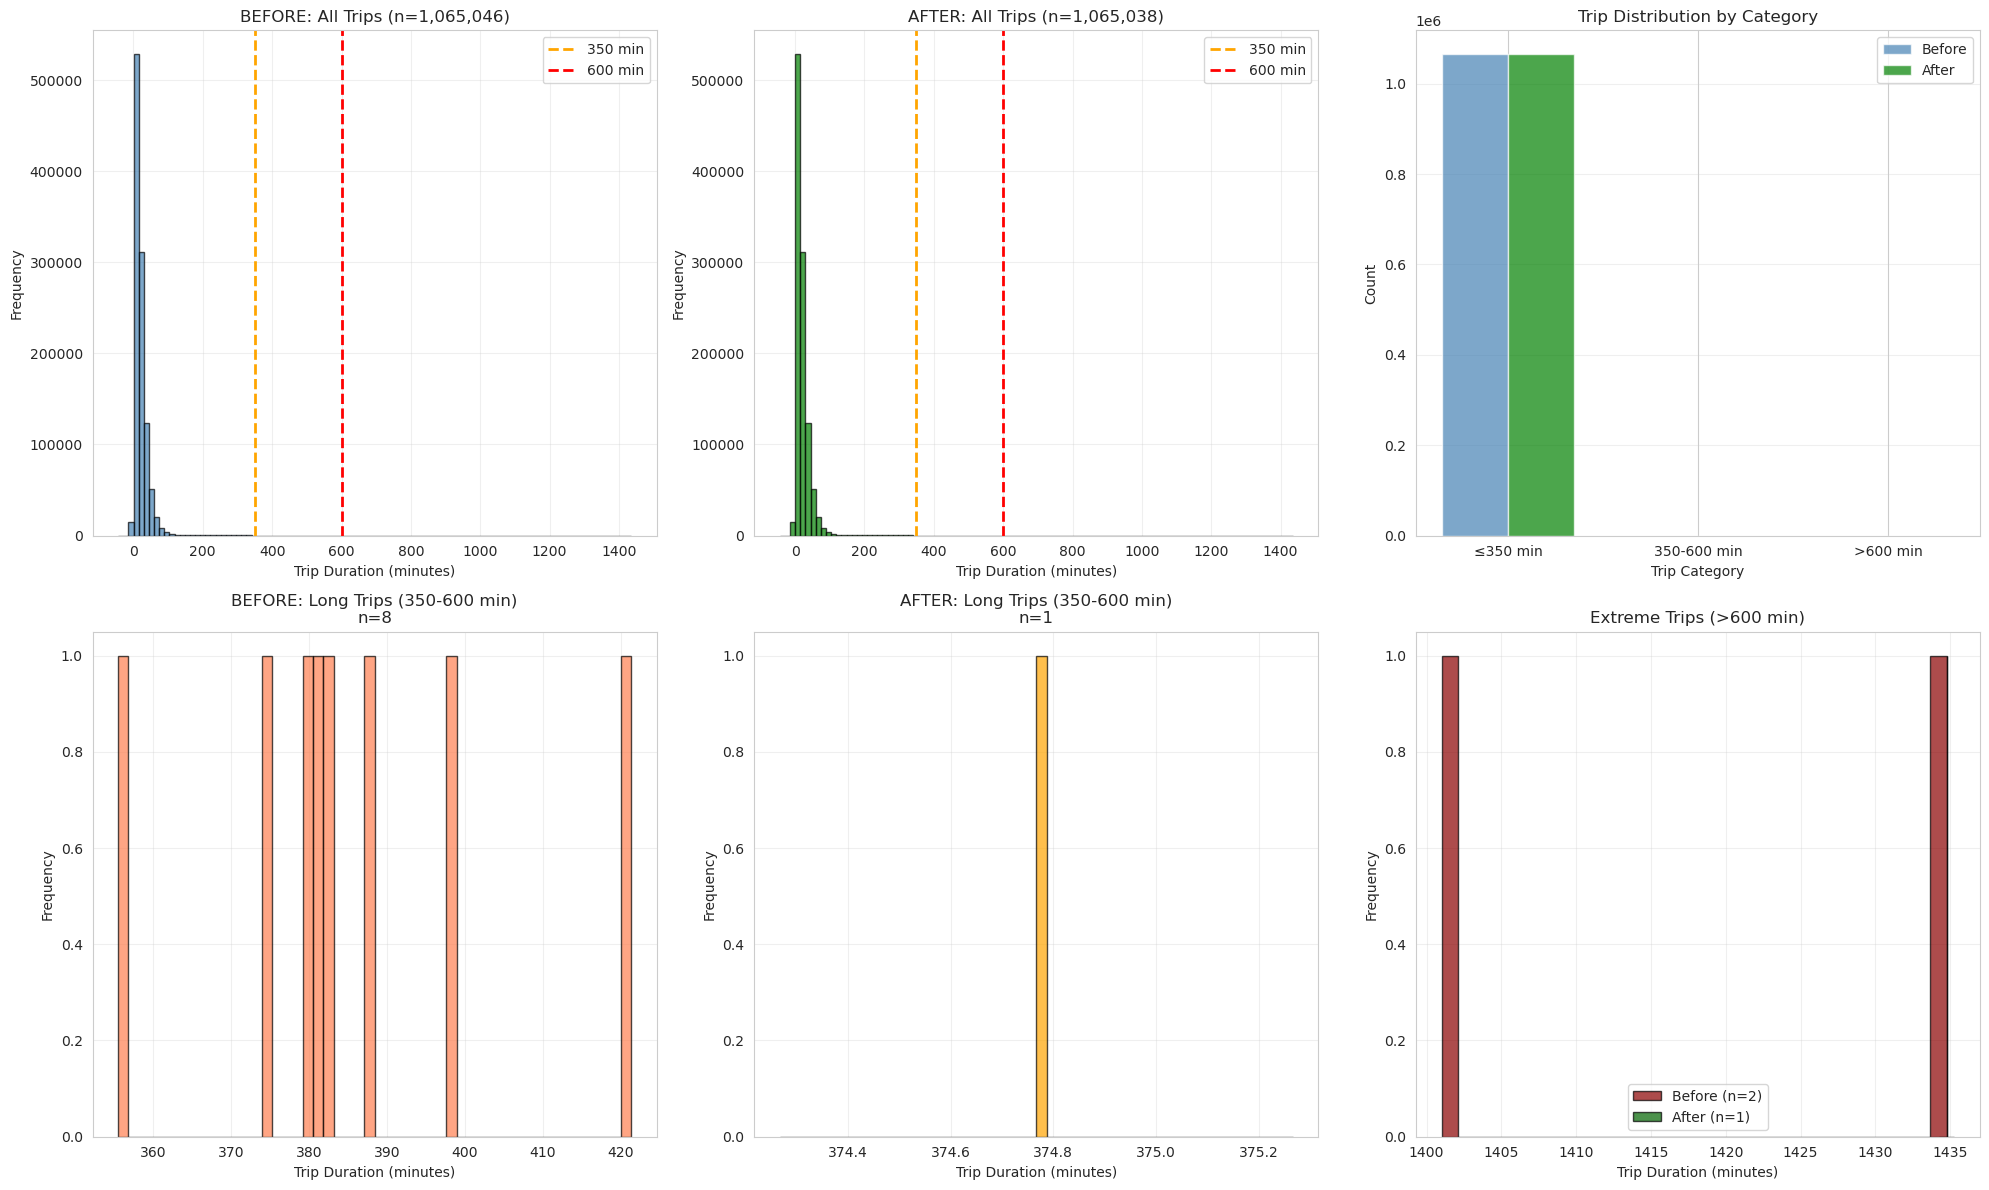

✅ Visualization saved to 'long_trips_removal_comparison.png'


In [18]:
# Compare distributions
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# Before - Full range
axes[0, 0].hist(df['trip_duration'], bins=100, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].axvline(threshold_long, color='orange', linestyle='--', linewidth=2, label=f'{threshold_long} min')
axes[0, 0].axvline(threshold_extreme, color='red', linestyle='--', linewidth=2, label=f'{threshold_extreme} min')
axes[0, 0].set_xlabel('Trip Duration (minutes)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title(f'BEFORE: All Trips (n={len(df):,})')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# After - Full range
axes[0, 1].hist(df_filtered['trip_duration'], bins=100, edgecolor='black', alpha=0.7, color='green')
axes[0, 1].axvline(threshold_long, color='orange', linestyle='--', linewidth=2, label=f'{threshold_long} min')
axes[0, 1].axvline(threshold_extreme, color='red', linestyle='--', linewidth=2, label=f'{threshold_extreme} min')
axes[0, 1].set_xlabel('Trip Duration (minutes)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title(f'AFTER: All Trips (n={len(df_filtered):,})')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Comparison stacked
categories = ['≤350 min', '350-600 min', '>600 min']
before_counts = [normal_trips.sum(), long_trips.sum(), extreme_trips.sum()]
after_counts = [normal_trips_after.sum(), long_trips_after.sum(), extreme_trips_after.sum()]

x = np.arange(len(categories))
width = 0.35

axes[0, 2].bar(x - width/2, before_counts, width, label='Before', color='steelblue', alpha=0.7)
axes[0, 2].bar(x + width/2, after_counts, width, label='After', color='green', alpha=0.7)
axes[0, 2].set_xlabel('Trip Category')
axes[0, 2].set_ylabel('Count')
axes[0, 2].set_title('Trip Distribution by Category')
axes[0, 2].set_xticks(x)
axes[0, 2].set_xticklabels(categories)
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3, axis='y')

# Before - Long trips (350-600 min)
long_before = df[(df['trip_duration'] > threshold_long) & (df['trip_duration'] <= threshold_extreme)]['trip_duration']
axes[1, 0].hist(long_before, bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[1, 0].set_xlabel('Trip Duration (minutes)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title(f'BEFORE: Long Trips ({threshold_long}-{threshold_extreme} min)\nn={len(long_before):,}')
axes[1, 0].grid(True, alpha=0.3)

# After - Long trips (350-600 min)
long_after = df_filtered[(df_filtered['trip_duration'] > threshold_long) & (df_filtered['trip_duration'] <= threshold_extreme)]['trip_duration']
axes[1, 1].hist(long_after, bins=50, edgecolor='black', alpha=0.7, color='orange')
axes[1, 1].set_xlabel('Trip Duration (minutes)')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title(f'AFTER: Long Trips ({threshold_long}-{threshold_extreme} min)\nn={len(long_after):,}')
axes[1, 1].grid(True, alpha=0.3)

# Before/After - Extreme trips (>600 min)
extreme_before = df[df['trip_duration'] > threshold_extreme]['trip_duration']
extreme_after = df_filtered[df_filtered['trip_duration'] > threshold_extreme]['trip_duration']

axes[1, 2].hist(extreme_before, bins=30, edgecolor='black', alpha=0.7, color='darkred', label=f'Before (n={len(extreme_before):,})')
axes[1, 2].hist(extreme_after, bins=30, edgecolor='black', alpha=0.7, color='darkgreen', label=f'After (n={len(extreme_after):,})')
axes[1, 2].set_xlabel('Trip Duration (minutes)')
axes[1, 2].set_ylabel('Frequency')
axes[1, 2].set_title(f'Extreme Trips (>{threshold_extreme} min)')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('long_trips_removal_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Visualization saved to 'long_trips_removal_comparison.png'")

## 6. Save Filtered Data Back to CSV

In [19]:
# Drop the temporary trip_duration column before saving
df_filtered_save = df_filtered.drop(columns=['trip_duration'])

print("="*80)
print("SAVING FILTERED DATA")
print("="*80)
print(f"Saving to: {csv_file}")
print(f"Rows: {len(df_filtered_save):,}")
print(f"Columns: {len(df_filtered_save.columns)}")

# Save back to the same CSV file
df_filtered_save.to_csv(csv_file, index=False)

print("\n✅ Filtered data saved successfully!")
print(f"   Original: {len(df):,} trips")
print(f"   Filtered: {len(df_filtered_save):,} trips")
print(f"   Removed:  {len(df) - len(df_filtered_save):,} trips ({(len(df) - len(df_filtered_save))/len(df)*100:.2f}%)")

SAVING FILTERED DATA
Saving to: bq-results-20251021-151536-1761059869369.csv
Rows: 1,065,038
Columns: 24

✅ Filtered data saved successfully!
   Original: 1,065,046 trips
   Filtered: 1,065,038 trips
   Removed:  8 trips (0.00%)

✅ Filtered data saved successfully!
   Original: 1,065,046 trips
   Filtered: 1,065,038 trips
   Removed:  8 trips (0.00%)


## 7. Verification

In [20]:
# Reload the CSV to verify
df_verify = pd.read_csv(csv_file, dtype_backend='pyarrow')
df_verify['pickup_datetime'] = pd.to_datetime(df_verify['pickup_datetime'])
df_verify['dropoff_datetime'] = pd.to_datetime(df_verify['dropoff_datetime'])
df_verify['trip_duration'] = (df_verify['dropoff_datetime'] - df_verify['pickup_datetime']).dt.total_seconds() / 60

print("="*80)
print("VERIFICATION - Reloaded CSV")
print("="*80)
print(f"Total trips: {len(df_verify):,}")

# Verify breakdown
verify_normal = df_verify['trip_duration'] <= threshold_long
verify_long = (df_verify['trip_duration'] > threshold_long) & (df_verify['trip_duration'] <= threshold_extreme)
verify_extreme = df_verify['trip_duration'] > threshold_extreme

print(f"\nTrip breakdown:")
print(f"  ≤{threshold_long} min (Normal):        {verify_normal.sum():,} ({verify_normal.sum()/len(df_verify)*100:.2f}%)")
print(f"  {threshold_long}-{threshold_extreme} min (Long):      {verify_long.sum():,} ({verify_long.sum()/len(df_verify)*100:.2f}%)")
print(f"  >{threshold_extreme} min (Extreme):       {verify_extreme.sum():,} ({verify_extreme.sum()/len(df_verify)*100:.2f}%)")

print("\nTrip Duration Statistics:")
print(df_verify['trip_duration'].describe())

print("\n✅ CSV file successfully updated and verified!")
print(f"✅ Two-stage filtering complete:")
print(f"   - Removed {len(indices_to_remove_stage1):,} extreme trips (99% of >{threshold_extreme} min)")
print(f"   - Removed {len(indices_to_remove_stage2):,} long trips (95% of {threshold_long}-{threshold_extreme} min)")
print(f"   - Total removed: {len(indices_to_remove):,} trips ({len(indices_to_remove)/len(df)*100:.2f}%)")

VERIFICATION - Reloaded CSV
Total trips: 1,065,038

Trip breakdown:
  ≤350 min (Normal):        1,065,036 (100.00%)
  350-600 min (Long):      1 (0.00%)
  >600 min (Extreme):       1 (0.00%)

Trip Duration Statistics:
count    1.065038e+06
mean     1.997282e+01
std      1.758339e+01
min     -4.398333e+01
25%      8.733333e+00
50%      1.500000e+01
75%      2.600000e+01
max      1.434783e+03
Name: trip_duration, dtype: float64

✅ CSV file successfully updated and verified!
✅ Two-stage filtering complete:
   - Removed 1 extreme trips (99% of >600 min)
   - Removed 7 long trips (95% of 350-600 min)
   - Total removed: 8 trips (0.00%)


## Summary

**What was done:**
1. Loaded original CSV with all trips
2. Calculated trip duration for each trip
3. **Stage 1**: Identified and randomly removed 99% of extreme trips (>600 minutes)
4. **Stage 2**: Identified and randomly removed 95% of long trips (350-600 minutes)
5. Saved the filtered data back to the same CSV file
6. Verified the changes with comprehensive statistics

**Two-Stage Filtering Strategy:**
- **Stage 1 (Extreme outliers)**: Aggressively remove 99% of trips >600 min (likely data errors)
- **Stage 2 (Long trips)**: Moderately remove 95% of trips 350-600 min (unusual but valid trips)
- **Preservation**: Keep 1% of extreme trips and 5% of long trips for data diversity

**Result:**
- The CSV file has been updated with the filtered data
- Extreme outliers significantly reduced while maintaining sample diversity
- All normal trips (≤350 min) remain unchanged